# MercaRAG — RAG multimodal con PostgreSQL + pgvector
Adaptación del **laboratorio pgvector multimodal** al dominio del supermercado (Entrega 1).

El sistema guarda documentos (fichas de producto, políticas, manuales y guías) y fotos de productos en PostgreSQL,
los convierte en vectores, busca por similitud con **pgvector** y le pasa lo encontrado a un LLM (Groq) para que redacte la respuesta.

| Ruta | Consulta | Se compara contra | Modelo | Dim. | Requerimiento |
|---|---|---|---|---|---|
| Texto → Texto | pregunta | chunks (3 estrategias) | multilingual-e5-small | 384 | RF-04, RF-06 |
| Texto → Imagen | descripción | fotos del catálogo | CLIP texto multilingüe | 512 | RF-09 |
| Imagen → Imagen | foto | fotos del catálogo | CLIP imagen | 512 | |
| Imagen → Texto | foto | chunks en espacio CLIP | CLIP | 512 | |
| Productos similares | descripción | fichas de producto | e5-small | 384 | RF-04 |
| Híbrida | descripción + sede + precio | fichas + inventario | e5-small + SQL | 384 | RF-05 |

**Regla de oro:** solo se comparan vectores del mismo espacio. Un vector de 384 nunca se compara con uno de 512.

e5 usa prefijos: los chunks se vectorizan como `passage: título. chunk` y las preguntas como `query: pregunta` (lo hace el paquete).

El código está en el paquete `mercarag/` (junto a este notebook); aquí se ejecuta paso a paso.

## 1. Importaciones y configuración

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mercarag import config, db, documentos, chunking, carga, busqueda, rag
from mercarag.embeddings import Modelos, abrir_imagen

pd.set_option("display.max_colwidth", 120)
print("Modelo de texto :", config.MODELO_TEXTO)
print("CLIP imagen     :", config.MODELO_CLIP_IMAGEN)
print("CLIP texto      :", config.MODELO_CLIP_TEXTO)
print("LLM             :", config.LLM_MODEL, "| llave Groq:", "sí" if config.GROQ_API_KEY else "no (se omite la generación)")
print("Parámetros de chunking (Entrega 1):")
for estrategia, params in config.PARAMETROS_CHUNKING.items():
    print(f"  {estrategia:10s} {params}")

Modelo de texto : intfloat/multilingual-e5-small
CLIP imagen     : sentence-transformers/clip-ViT-B-32
CLIP texto      : sentence-transformers/clip-ViT-B-32-multilingual-v1
LLM             : openai/gpt-oss-120b | llave Groq: sí
Parámetros de chunking (Entrega 1):
  fijo       {'chunk_size': 256, 'chunk_overlap': 32}
  oraciones  {'max_sentences': 5, 'overlap': 1, 'spacy_model': 'es_core_news_sm', 'max_tokens': 464}
  semantico  {'threshold': 0.8, 'max_tokens': 464, 'min_tokens': 16}


## 2. Conexión a PostgreSQL
`autocommit = True` evita que un error deje la sesión en *current transaction is aborted*; las cargas abren su propia transacción.
`register_vector` permite pasar arreglos de NumPy directamente como parámetros `%s`.

In [2]:
conn = db.get_connection()
with conn.cursor() as cur:
    cur.execute("SELECT version()")
    print(cur.fetchone()[0])
print("pgvector", db.version_pgvector(conn))

# El esquema (schema.sql) y los datos del dominio (sql/02_datos_dominio.sql) los carga Docker al crear la base
with conn.cursor() as cur:
    cur.execute("""SELECT (SELECT count(*) FROM producto), (SELECT count(*) FROM inventario),
                          (SELECT count(*) FROM compra), (SELECT count(*) FROM domicilio)""")
    p, i, c, d = cur.fetchone()
print(f"Productos: {p}  Inventario: {i}  Compras: {c}  Domicilios: {d}")
assert p > 0, "La base no tiene datos: ejecute 'docker compose down -v' y 'docker compose up -d' para recrearla"

PostgreSQL 17.11 (Debian 17.11-1.pgdg12+2) on x86_64-pc-linux-gnu, compiled by gcc (Debian 12.2.0-14+deb12u1) 12.2.0, 64-bit
pgvector 0.8.7
Productos: 1215  Inventario: 5164  Compras: 30000  Domicilios: 20043


## 3. Carga de modelos
La primera vez se descargan (~1,4 GB) y quedan en el volumen `modelos_hf`. Las dimensiones se **calculan** y se comparan con las columnas `VECTOR(n)` del esquema.

In [3]:
modelos = Modelos()
dims = modelos.dimensiones()
print(dims)
assert dims["texto"] == config.DIM_TEXTO, "multilingual-e5-small debe dar 384 dimensiones (VECTOR(384))"
assert dims["clip_texto"] == dims["clip_imagen"] == config.DIM_CLIP, "CLIP debe dar 512 dimensiones (VECTOR(512))"

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (35 outputs left out)

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

{'texto': 384, 'clip_texto': 512, 'clip_imagen': 512}


## 4. (Opcional) Reiniciar la capa RAG
Con `REINICIAR_RAG = True` se borran documentos, imágenes, vectores y consultas, **sin tocar** los datos del negocio
(productos, inventario, compras). Útil si cambian los modelos o los parámetros de chunking.

In [4]:
REINICIAR_RAG = False

if REINICIAR_RAG:
    with conn.cursor() as cur:
        cur.execute("""TRUNCATE evaluacion, resultado, query_embeddings, consulta, pregunta_documento, pregunta,
                                embeddings_texto_clip, embeddings_texto, embeddings_imagen,
                                imagen_etiqueta, etiqueta, imagen, documento RESTART IDENTITY CASCADE""")
    print("Capa RAG reiniciada")

## 5. Documentos y las tres estrategias de chunking
Los documentos están en `data/documentos/` (Markdown con encabezado de metadatos; también se aceptan `.txt` y `.pdf`).
Cada ficha trae `codigo_barras`, que la enlaza con su producto (`documento.id_producto`): ese es el puente entre el RAG y el negocio.
Políticas, manuales y guías no describen un producto (la base lo exige con un CHECK).

Solo se fragmentan estos documentos: productos, clientes y compras son filas SQL y entran al RAG como filtros.

In [5]:
docs = documentos.cargar_documentos()
print(f"{len(docs)} documentos")
pd.DataFrame(docs)[["codigo_doc", "tipo", "titulo", "codigo_barras"]].groupby("tipo").head(3)

93 documentos


,codigo_doc,tipo,titulo,codigo_barras
0,FICHA_ACEITE_DE_GIRASOL,ficha,Ficha de producto - Aceite de girasol,7700000005267
1,FICHA_AGUA_CON_GAS,ficha,Ficha de producto - Agua con gas,7700000006769
2,FICHA_AGUA_SIN_GAS,ficha,Ficha de producto - Agua sin gas,7700000006165
81,GUIA_CAFE_CALDAS,guia,Guía del café de Caldas,NaN
82,GUIA_ETIQUETADO,guia,Guía para leer el etiquetado nutricional y los alérgenos,NaN
83,GUIA_PUNTOS_VENTA,guia,Guía de puntos de venta y horarios,NaN
85,MAN_CADENA_FRIO,manual,Manual de cadena de frío y manejo de perecederos,NaN
86,MAN_CAJA,manual,Manual de caja y medios de pago,NaN
87,MAN_CONDUCTORES,manual,Manual del conductor de domicilios,NaN
89,POL_DATOS_PERSONALES,politica,Política de tratamiento de datos personales,NaN


Así parte cada estrategia el mismo documento (parámetros congelados en `config.py`, medidos con el tokenizador de e5):
el **fijo** corta cada 256 tokens con 32 de solapamiento (puede partir una oración), el de **oraciones** agrupa hasta 5 oraciones
completas que se solapan 1, y el **semántico** corta cuando la similitud con el chunk en construcción baja de 0,80.

In [6]:
doc = next(d for d in docs if d["codigo_doc"] == "POL_DOMICILIOS")
for estrategia in config.ESTRATEGIAS:
    chunks, usados = chunking.generar_chunks(doc["contenido_texto"], estrategia, modelos)
    print(f"\n===== {estrategia.upper()} -> {len(chunks)} chunks  {usados}")
    for i, ch in enumerate(chunks[:3]):
        print(f"  [{i}] ({modelos.contar_tokens(ch)} tokens) {ch[:160]}...")


===== FIJO -> 4 chunks  {'chunk_size': 256, 'chunk_overlap': 32, 'tokenizador': 'intfloat/multilingual-e5-small', 'herramienta': 'tokenizador del modelo (offsets)'}
  [0] (258 tokens) Política del servicio de domicilios.

Cobertura.
El servicio de domicilios cubre el área urbana de Manizales y el municipio de Villamaría. Cada pedido se despac...
  [1] (257 tokens) ea alta y Bosques del Norte, se cobra un recargo de 2.000 pesos. Los clientes que compran más de cuatro veces al mes acceden al plan de domicilio gratis sin imp...
  [2] (258 tokens) de salir de la sede o porque no fue posible entregarlo.

Un domicilio solo puede cancelarse sin costo mientras está pendiente. Si ya está en ruta, la cancelació...

===== ORACIONES -> 9 chunks  {'max_sentences': 5, 'overlap': 1, 'spacy_model': 'es_core_news_sm', 'max_tokens': 464, 'tokenizador': 'intfloat/multilingual-e5-small', 'herramienta': 'spaCy + agrupación propia'}
  [0] (97 tokens) Política del servicio de domicilios. Cobertura. El servi

## 6. Catálogo de fotos
Las fotos van en `data/imagenes/<producto_base>/` (ver `data/imagenes/LEEME.md`). Cada foto pertenece a **una sola** ficha (su único dueño);
el producto que muestra se obtiene por esa ficha. Por cada foto se calcula el SHA-256
(para no duplicarla), el ancho y alto (corrigiendo la orientación EXIF) y la ruta relativa a `data/`.

In [7]:
catalogo = carga.catalogo_imagenes()
print(f"{len(catalogo)} fotos encontradas")
if not catalogo:
    print("⚠ No hay fotos en data/imagenes/. Las rutas con imágenes se omitirán; vea data/imagenes/LEEME.md")
pd.DataFrame(catalogo)[["codigo_img", "ruta_archivo", "codigo_doc", "ancho", "alto", "etiquetas"]].head(10) if catalogo else None

/usr/local/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


326 fotos encontradas


,codigo_img,ruta_archivo,codigo_doc,ancho,alto,etiquetas
0,IMG_ACEITE_DE_GIRASOL_4a94e4a6,imagenes/aceite_de_girasol/297791_1_238.webp,FICHA_ACEITE_DE_GIRASOL,500,500,[aceite de girasol]
1,IMG_ACEITE_DE_GIRASOL_3c0a3e87,imagenes/aceite_de_girasol/D_NQ_NP_642469-MLA116019668102_092026-O.webp,FICHA_ACEITE_DE_GIRASOL,500,500,[aceite de girasol]
2,IMG_ACEITE_DE_GIRASOL_ef0f96a9,imagenes/aceite_de_girasol/canola-girasol-x-1000.jpg,FICHA_ACEITE_DE_GIRASOL,500,500,[aceite de girasol]
3,IMG_ACEITE_DE_GIRASOL_748f0b05,imagenes/aceite_de_girasol/images.jpg,FICHA_ACEITE_DE_GIRASOL,399,501,[aceite de girasol]
4,IMG_AGUA_CON_GAS_cec0a6ae,imagenes/agua_con_gas/Agua-Con-Gas-600-ml-193043_a.webp,FICHA_AGUA_CON_GAS,1000,1000,[agua con gas]
5,IMG_AGUA_CON_GAS_e493924b,imagenes/agua_con_gas/Agua-con-gass.webp,FICHA_AGUA_CON_GAS,1200,1200,[agua con gas]
6,IMG_AGUA_CON_GAS_7900fe3d,imagenes/agua_con_gas/agua-manantial-con-gas-botella-600mlagua-manantial-con-gas-botella-600mlmanantiallicores-medel...,FICHA_AGUA_CON_GAS,810,891,[agua con gas]
7,IMG_AGUA_CON_GAS_37f49a25,imagenes/agua_con_gas/images.jpg,FICHA_AGUA_CON_GAS,333,600,[agua con gas]
8,IMG_AGUA_SIN_GAS_c3547da2,imagenes/agua_sin_gas/59673-1-AGUA-MANANTIAL-FCO-X-600ML.webp,FICHA_AGUA_SIN_GAS,1000,1000,[agua sin gas]
9,IMG_AGUA_SIN_GAS_3db0f1d5,imagenes/agua_sin_gas/AGUA-PURA-SIN-GAS-1375498_a.webp,FICHA_AGUA_SIN_GAS,507,1000,[agua sin gas]


## 7. Carga transaccional (idempotente)
`INSERT ... ON CONFLICT ... DO UPDATE ... RETURNING id`: se puede ejecutar varias veces sin duplicar.
Se guardan los chunks de **las tres estrategias** en `embeddings_texto` (columna `estrategia_chunking`), con su vector e5 (384),
sus `n_tokens` (nunca más de 512) y su vector CLIP de texto (`embeddings_texto_clip`, para la ruta imagen → texto).
Las etiquetas de cada foto van al catálogo `etiqueta` y a la tabla N:M `imagen_etiqueta`. Si algo falla: `ROLLBACK`.

In [8]:
resumen_docs = carga.cargar_documentos(conn, docs, modelos)
print(resumen_docs)
if catalogo:
    resumen_img = carga.cargar_imagenes(conn, catalogo, modelos)
    print({k: v for k, v in resumen_img.items() if k != "omitidas"})
    if resumen_img["omitidas"]:
        print("Fotos sin ficha (carpeta mal nombrada):", resumen_img["omitidas"][:10])

Batches:   0%|          | 0/21 [00:00<?, ?it/s]

Batches:   0%|          | 0/21 [00:00<?, ?it/s]

{'documentos': 93, 'chunks': 650, 'por_estrategia': {'fijo': 165, 'oraciones': 381, 'semantico': 104}, 'consultas_borradas': 0, 'segundos': 138.35}


/usr/local/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


{'imagenes': 326, 'segundos': 34.0}


## 8. Verificación de integridad
`LEFT JOIN ... IS NULL`: ningún documento sin sus tres estrategias, ningún chunk ni imagen sin vector y ningún chunk truncado.

In [9]:
integridad = carga.verificar_integridad(conn)
print(integridad)
assert integridad["docs_sin_chunks"] == 0
assert integridad["docs_sin_las_tres_estrategias"] == 0
assert integridad["chunks_truncados"] == 0
assert integridad["chunks_sin_vector_clip"] == 0
assert integridad["imagenes_sin_vector"] == 0
print("Integridad OK")

{'documentos': 93, 'chunks': 650, 'imagenes': 326, 'docs_sin_chunks': 0, 'docs_sin_las_tres_estrategias': 0, 'chunks_sin_vector_clip': 0, 'chunks_truncados': 0, 'imagenes_sin_vector': 0}
Integridad OK


## 9. Índices vectoriales HNSW
Hay un índice HNSW **parcial por estrategia** (`WHERE estrategia_chunking = ...`), uno para imágenes y uno para los chunks en espacio CLIP.
El operador del índice (`vector_cosine_ops`) debe coincidir con el de la consulta (`<=>`). Con pocas filas PostgreSQL prefiere `Seq Scan`,
así que para ver el índice se desactiva temporalmente.

In [10]:
print(pd.DataFrame(db.consultar(conn, """SELECT indexname, tablename FROM pg_indexes
                                       WHERE indexdef ILIKE '%hnsw%' ORDER BY indexname""", vectorial=False)))

q = modelos.embed_consulta(["horario de domicilios"])[0]
with conn.cursor() as cur:
    cur.execute("SET enable_seqscan = off")
    cur.execute("""EXPLAIN ANALYZE
                   SELECT id_embedding FROM embeddings_texto
                   WHERE estrategia_chunking = 'semantico'
                   ORDER BY vector_embedding <=> %s LIMIT 5""", (q,))
    print("\n".join(f[0] for f in cur.fetchall()))
    cur.execute("SET enable_seqscan = on")

                      indexname              tablename
0      idx_emb_imagen_desc_hnsw      embeddings_imagen
1           idx_emb_imagen_hnsw      embeddings_imagen
2       idx_emb_texto_clip_hnsw  embeddings_texto_clip
3       idx_emb_texto_hnsw_fijo       embeddings_texto
4  idx_emb_texto_hnsw_oraciones       embeddings_texto
5  idx_emb_texto_hnsw_semantico       embeddings_texto
Limit  (cost=4.01..24.07 rows=5 width=12) (actual time=0.101..0.111 rows=5 loops=1)
  ->  Index Scan using idx_emb_texto_hnsw_semantico on embeddings_texto  (cost=4.01..36.11 rows=8 width=12) (actual time=0.100..0.110 rows=5 loops=1)
        Order By: (vector_embedding <=> '[0.0010416554,-0.01287918,-0.0014375708,-0.08326932,0.021356866,-0.045327518,0.028105535,0.07405466,0.067770645,0.0077425516,0.0426817,0.06804965,0.027254622,-0.04568866,-0.06628046,0.01748801,0.04723332,-0.041337848,-0.018772103,-0.036345515,-0.022309188,-0.0007335704,-0.06887242,0.048295718,0.05242697,0.042329695,0.008990633,0.04972386,

## 10. Rutas de búsqueda
### 10.1 Texto → Texto (la misma pregunta con cada estrategia)

In [11]:
pregunta = "¿Hasta qué hora puedo pedir un domicilio un domingo?"
for estrategia in config.ESTRATEGIAS:
    print(f"\n--- {estrategia}")
    display(busqueda.buscar_texto_texto(conn, modelos, pregunta, estrategia=estrategia, k=3)
            [["codigo_doc", "chunk_id", "score", "contenido_chunk"]])


--- fijo


,codigo_doc,chunk_id,score,contenido_chunk
0,POL_DOMICILIOS,1,0.8741,"ea alta y Bosques del Norte, se cobra un recargo de 2.000 pesos. Los clientes que compran más de cuatro veces al mes..."
1,POL_DOMICILIOS,0,0.8704,Política del servicio de domicilios.\n\nCobertura.\nEl servicio de domicilios cubre el área urbana de Manizales y el...
2,GUIA_PUNTOS_VENTA,1,0.8596,"cierra más tarde, y domingos de 8:00 a. m. a 8:00 p. m. Es el centro de despacho principal de domicilios para el nor..."



--- oraciones


,codigo_doc,chunk_id,score,contenido_chunk
0,POL_DOMICILIOS,1,0.8926,"Si ninguna sede tiene el pedido completo, el sistema divide el pedido o le propone al cliente reemplazar los product..."
1,POL_DOMICILIOS,3,0.8762,Los clientes que compran más de cuatro veces al mes acceden al plan de domicilio gratis sin importar el valor del pe...
2,POL_DOMICILIOS,4,0.8612,Estados de un domicilio. Cada domicilio pasa por estados que el cliente puede consultar en la aplicación o por teléf...



--- semantico


,codigo_doc,chunk_id,score,contenido_chunk
0,POL_DOMICILIOS,0,0.8765,Política del servicio de domicilios. Cobertura. El servicio de domicilios cubre el área urbana de Manizales y el mun...
1,POL_DOMICILIOS,1,0.8507,"Entregado: el cliente recibió el pedido; se registra la hora exacta de entrega. Cancelado: el pedido se anuló, ya se..."
2,GUIA_PUNTOS_VENTA,0,0.8529,"Guía de puntos de venta y horarios. MercaRAG Cable. Ubicado en la carrera 23 # 64-15, en el barrio El Cable, frente ..."


Búsqueda con filtro relacional (solo manuales): el `WHERE` y el `ORDER BY <=>` van en el mismo SQL.

In [12]:
busqueda.buscar_texto_texto(conn, modelos, "temperatura de los lácteos", estrategia="oraciones", k=3, tipo="manual")

,id_embedding,id_doc,codigo_doc,titulo,tipo,chunk_id,estrategia,contenido_chunk,score,score_rrf
0,560,86,MAN_CADENA_FRIO,Manual de cadena de frío y manejo de perecederos,manual,1,oraciones,"Rangos de temperatura. Los lácteos, huevos refrigerados, embutidos y carnes frescas se conservan entre 0 °C y 4 °C. ...",0.9070,0.03252
1,561,86,MAN_CADENA_FRIO,Manual de cadena de frío y manejo de perecederos,manual,2,oraciones,Ningún producto refrigerado debe permanecer más de 20 minutos fuera del frío durante la recepción o el alistamiento ...,0.8991,0.03200
2,559,86,MAN_CADENA_FRIO,Manual de cadena de frío y manejo de perecederos,manual,0,oraciones,"Manual de cadena de frío y manejo de perecederos. Objetivo. Este manual describe cómo recibir, almacenar, exhibir y ...",0.8340,0.03132


### 10.2 RF-04 — Productos similares a una descripción

In [13]:
busqueda.productos_similares(conn, modelos, "algo dulce para untar en galletas", k=8)

,producto_base,producto,marca,categoria,precio,score
0,Galletas con chips de chocolate,Galletas con chips de chocolate Noel pack x6,Noel,Snacks y dulces,5100.00,0.8435
1,Galletas con chips de chocolate,Galletas con chips de chocolate Jet pack x6,Jet,Snacks y dulces,5500.00,0.8435
2,Galletas con chips de chocolate,Galletas con chips de chocolate Margarita pack x6,Margarita,Snacks y dulces,5700.00,0.8435
3,Galletas con chips de chocolate,Galletas con chips de chocolate Colombina pack x6,Colombina,Snacks y dulces,6200.00,0.8435
4,Galletas con chips de chocolate,Galletas con chips de chocolate Frito Lay pack x6,Frito Lay,Snacks y dulces,6650.00,0.8435
5,Galletas con chips de chocolate,Galletas con chips de chocolate Noel pack x12,Noel,Snacks y dulces,10050.00,0.8435
6,Galletas con chips de chocolate,Galletas con chips de chocolate Jet pack x12,Jet,Snacks y dulces,10700.00,0.8435
7,Galletas con chips de chocolate,Galletas con chips de chocolate Margarita pack x12,Margarita,Snacks y dulces,11250.00,0.8435


### 10.3 RF-05 — Búsqueda híbrida
Descripción en lenguaje natural + disponible (`stock > 0`) en una sede + precio máximo (+ promoción vigente opcional).

In [14]:
busqueda.buscar_productos_hibrida(conn, modelos, "café para preparar en greca",
                                  sede="MercaRAG Chipre", precio_max=20000, k=8)

,producto,marca,precio,sede,stock,promocion,score
0,Café molido tostado Corona 250 g,Corona,10650.00,MercaRAG Chipre,28,Café de Caldas a mitad de precio en la segunda unidad,0.8564
1,Café molido tostado Águila Roja 250 g,Águila Roja,11500.00,MercaRAG Chipre,91,Café de Caldas a mitad de precio en la segunda unidad,0.8564
2,Café molido tostado Juan Valdez 250 g,Juan Valdez,13100.00,MercaRAG Chipre,58,Café de Caldas a mitad de precio en la segunda unidad,0.8564
3,Café molido tostado Corona 500 g,Corona,19550.00,MercaRAG Chipre,96,Café de Caldas a mitad de precio en la segunda unidad,0.8564
4,Papas a la francesa congeladas Pietrán 500 g,Pietrán,8200.00,MercaRAG Chipre,83,NaN,0.8518
5,Papas a la francesa congeladas Frescampo 500 g,Frescampo,8850.00,MercaRAG Chipre,41,NaN,0.8518
6,Papas a la francesa congeladas Zenú 500 g,Zenú,9100.00,MercaRAG Chipre,10,NaN,0.8518
7,Papas a la francesa congeladas McCain 500 g,McCain,9950.00,MercaRAG Chipre,36,NaN,0.8518


In [15]:
busqueda.buscar_productos_hibrida(conn, modelos, "comida para mi perro", solo_promocion=True, k=5)

,producto,marca,precio,sede,stock,promocion,score
0,Alimento seco para perro adulto Whiskas 2 kg,Whiskas,29850.00,MercaRAG La Enea,33,Mascotas felices,0.8882
1,Alimento seco para perro adulto Whiskas 2 kg,Whiskas,29850.00,MercaRAG Chipre,120,Mascotas felices,0.8882
2,Alimento seco para perro adulto Whiskas 2 kg,Whiskas,29850.00,MercaRAG Milán,97,Mascotas felices,0.8882
3,Alimento seco para perro adulto Whiskas 2 kg,Whiskas,29850.00,MercaRAG Centro,37,Mascotas felices,0.8882
4,Alimento seco para perro adulto Chunky 2 kg,Chunky,30700.00,MercaRAG Milán,106,Mascotas felices,0.8882


### 10.4 RF-09 — Texto → Imagen
Con CLIP los scores texto→imagen suelen estar entre 0,15 y 0,35: importa el **orden**, no el valor absoluto.

,id_img,codigo_img,ruta_archivo,descripcion,codigo_doc,producto,categoria,score
0,213,IMG_LULO_5bf632fb,imagenes/lulo/images.jpg,lulo,FICHA_LULO,Lulo Huerta Caldense 500 g,Frutas y verduras,0.2766
1,195,IMG_LECHUGA_CRESPA_e0df58ff,imagenes/lechuga_crespa/Lechuga-Verde-Crespa-En-Bolsa-X-200-gr-839802_a.webp,lechuga crespa,FICHA_LECHUGA_CRESPA,Lechuga crespa Huerta Caldense 1 und,Frutas y verduras,0.2743
2,197,IMG_LECHUGA_CRESPA_b183374a,imagenes/lechuga_crespa/images (2).jpg,lechuga crespa,FICHA_LECHUGA_CRESPA,Lechuga crespa Huerta Caldense 1 und,Frutas y verduras,0.2740
3,307,IMG_TOMATE_CHONTO_b58d7c51,imagenes/tomate_chonto/20220809173228-Verduras-Verduras-MallasBolsas-Tomate-Chonto-3libras--Malla-187202208091732283...,tomate chonto,FICHA_TOMATE_CHONTO,Tomate chonto Huerta Caldense 500 g,Frutas y verduras,0.2740


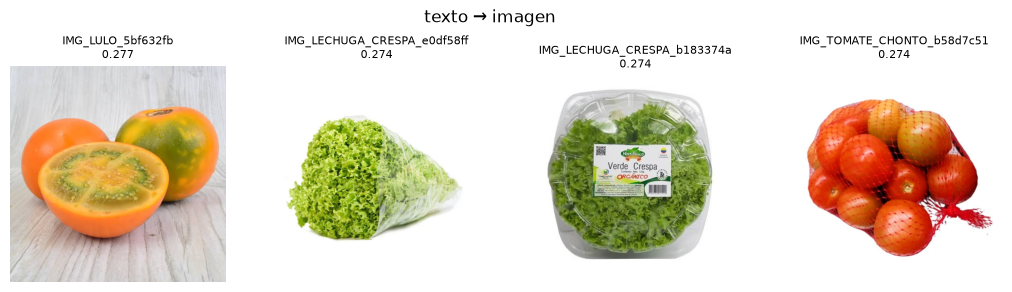

In [16]:
def mostrar_fotos(df, titulo=""):
    if df is None or df.empty:
        print("Sin resultados (¿hay fotos en data/imagenes/?)")
        return
    fig, ejes = plt.subplots(1, len(df), figsize=(3.2 * len(df), 3.4))
    ejes = np.atleast_1d(ejes)
    for eje, fila in zip(ejes, df.itertuples()):
        eje.imshow(abrir_imagen(config.DATA_DIR / fila.ruta_archivo))
        eje.set_title(f"{fila.codigo_img}\n{fila.score:.3f}", fontsize=8)
        eje.axis("off")
    fig.suptitle(titulo)
    plt.show()

res_img = busqueda.buscar_texto_imagen(conn, modelos, "Fruta verde ", k=4)
display(res_img)
mostrar_fotos(res_img, "texto → imagen")

### 10.5 Imagen → Imagen e Imagen → Texto
Con una foto de `data/consultas/` (que no está en la base).

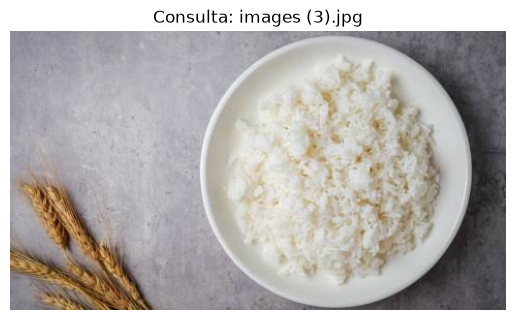

,id_img,codigo_img,ruta_archivo,codigo_doc,producto,score
0,44,IMG_ARROZ_BLANCO_40e91e42,imagenes/arroz_blanco/images.jpg,FICHA_ARROZ_BLANCO,Arroz blanco Diana 500 g,0.8870
1,43,IMG_ARROZ_BLANCO_bccc8f14,imagenes/arroz_blanco/images (2).jpg,FICHA_ARROZ_BLANCO,Arroz blanco Diana 500 g,0.8626
2,31,IMG_AREPA_DE_MAIZ_BLANCO_0e799b62,imagenes/arepa_de_maiz_blanco/images (3).jpg,FICHA_AREPA_DE_MAIZ_BLANCO,Arepa de maíz blanco Bimbo x5,0.7516
3,29,IMG_AREPA_DE_MAIZ_BLANCO_2222d4e7,imagenes/arepa_de_maiz_blanco/images (1).jpg,FICHA_AREPA_DE_MAIZ_BLANCO,Arepa de maíz blanco Bimbo x5,0.7504


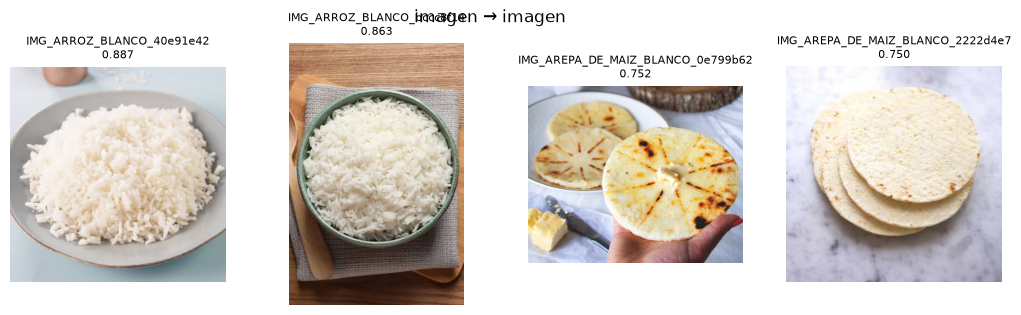

,id_embedding,id_doc,codigo_doc,titulo,tipo,chunk_id,estrategia,contenido_chunk,score
0,52,8,FICHA_AREPA_DE_MAIZ_BLANCO,Ficha de producto - Arepa de maíz blanco,ficha,0,semantico,"Ficha de producto: Arepa de maíz blanco. Descripción. Arepas redondas y delgadas de maíz blanco, listas para asar y ...",0.2659
1,354,56,FICHA_MANTEQUILLA_CON_SAL,Ficha de producto - Mantequilla con sal,ficha,0,semantico,"Ficha de producto: Mantequilla con sal. Descripción. Mantequilla de barra amarilla, para untar en pan y arepas o par...",0.2650
2,554,85,GUIA_RECETAS,Recetas típicas con productos del supermercado,guia,0,semantico,Recetas típicas con productos del supermercado. Frijoles antioqueños. Remoje 500 gramos de fríjol cargamanto la noch...,0.2603
3,245,39,FICHA_HARINA_DE_MAIZ_PRECOCIDA,Ficha de producto - Harina de maíz precocida,ficha,0,semantico,Ficha de producto: Harina de maíz precocida. Descripción. Harina de maíz blanco precocida para preparar arepas en mi...,0.2603
4,72,11,FICHA_ARROZ_BLANCO,Ficha de producto - Arroz blanco,ficha,0,semantico,"Ficha de producto: Arroz blanco. Descripción. Arroz blanco de grano largo, suelto al cocinar, básico de la cocina co...",0.2593


In [17]:
fotos_consulta = sorted(p for p in config.CONSULTAS_DIR.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})
if fotos_consulta and catalogo:
    foto = fotos_consulta[0]
    plt.imshow(abrir_imagen(foto)); plt.axis("off"); plt.title(f"Consulta: {foto.name}"); plt.show()
    res = busqueda.buscar_imagen_imagen(conn, modelos, foto, k=4)
    display(res); mostrar_fotos(res, "imagen → imagen")
    display(busqueda.buscar_imagen_texto(conn, modelos, foto, k=5))
else:
    print("Agregue fotos en data/imagenes/ y al menos una en data/consultas/ para probar estas rutas")

## 11. RAG — respuesta en lenguaje natural (RF-06)
El LLM solo lee texto: los chunks recuperados (y los metadatos de las fotos) se convierten en un bloque de contexto.
El *system prompt* obliga a responder solo con ese contexto. Sin `GROQ_API_KEY` la respuesta es `None` y lo demás sigue funcionando.

> Si Groq responde `404 model_not_found`, cambie `LLM_MODEL` en `.env` por un modelo vigente de console.groq.com/docs/models y ejecute `docker compose up -d`.

In [18]:
salida = rag.preguntar(conn, modelos, "¿Cuánto cuesta el domicilio y cuánto se demora?", estrategia="semantico", k=4)
print(salida["contexto"][:1500])
print("\nRESPUESTA:\n", salida["respuesta"])
print(f"\nRecuperación: {salida['tiempo_recuperacion_ms']} ms | Total: {salida['tiempo_total_ms']} ms | id_consulta = {salida['id_consulta']}")

[1] Documento: POL_DOMICILIOS - Política del servicio de domicilios (score 0.876)
Política del servicio de domicilios. Cobertura. El servicio de domicilios cubre el área urbana de Manizales y el municipio de Villamaría. Cada pedido se despacha desde el punto de venta más cercano a la dirección de entrega que tenga todos los productos en inventario. Si ninguna sede tiene el pedido completo, el sistema divide el pedido o le propone al cliente reemplazar los productos agotados por otros similares de la misma categoría. Horarios. Los pedidos se reciben todos los días entre las 7:00 a. m. y las 8:00 p. m. Los pedidos hechos después de las 8:00 p. m. se programan para la primera franja del día siguiente. Los domingos y festivos el último pedido se recibe a las 6:00 p. m. Costos y pedido mínimo. El pedido mínimo es de 30.000 pesos. El domicilio cuesta 4.500 pesos para pedidos entre 30.000 y 99.999 pesos, y es gratis para pedidos de 100.000 pesos o más. Para Villamaría y los barrios de la peri

In [19]:
def preguntar(texto, estrategia="semantico"):
    s = rag.preguntar(conn, modelos, texto, estrategia=estrategia)
    print(s["respuesta"] or s["contexto"][:800])
    return s

_ = preguntar("¿Qué hago si me llega un producto vencido en el domicilio?")

Si al recibir el pedido notas que un producto está vencido, debes rechazarlo en el momento y avisarle al conductor, quien registrará la novedad. MercaRAG lo reemplazará sin costo y te entregará un bono de 5 000 pesos para tu próxima compra; el caso se registra en el sistema con el código de barras, lote y sede del producto [POL_DEVOLUCIONES] [POL_DOMICILIOS].


## 12. Trazabilidad
Cada consulta queda en `consulta`, sus vectores en `query_embeddings` (e5 384 y CLIP 512) y cada resultado en `resultado`,
con su posición, su score y el **chunk** exacto (o la foto) que se recuperó.

In [20]:
rag.historial(conn, n=3)

,id_consulta,fecha,email,tipo_consulta,estrategia,pregunta,posicion,recurso,score,tiempo_recuperacion_ms,tiempo_total_ms,respuesta
0,2,2026-11-25 00:06:38.618032,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,1,POL_DEVOLUCIONES #1,0.861200,85.12,1506.78,"Si al recibir el pedido notas que un producto está vencido, debes rechazarlo en"
1,2,2026-11-25 00:06:38.618032,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,2,POL_DEVOLUCIONES #0,0.857600,85.12,1506.78,"Si al recibir el pedido notas que un producto está vencido, debes rechazarlo en"
2,2,2026-11-25 00:06:38.618032,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,3,POL_DOMICILIOS #1,0.860600,85.12,1506.78,"Si al recibir el pedido notas que un producto está vencido, debes rechazarlo en"
3,2,2026-11-25 00:06:38.618032,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,4,MAN_CADENA_FRIO #1,0.848200,85.12,1506.78,"Si al recibir el pedido notas que un producto está vencido, debes rechazarlo en"
4,2,2026-11-25 00:06:38.618032,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,5,MAN_CADENA_FRIO #0,0.834900,85.12,1506.78,"Si al recibir el pedido notas que un producto está vencido, debes rechazarlo en"
5,2,2026-11-25 00:06:38.618032,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,6,IMG_DESODORANTE_EN_BARRA_9c2fc604,0.243200,85.12,1506.78,"Si al recibir el pedido notas que un producto está vencido, debes rechazarlo en"
6,2,2026-11-25 00:06:38.618032,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,7,IMG_BLANQUEADOR_35829d6f,0.241600,85.12,1506.78,"Si al recibir el pedido notas que un producto está vencido, debes rechazarlo en"
7,2,2026-11-25 00:06:38.618032,empleado1@mercarag.co,rag,semantico,¿Qué hago si me llega un producto vencido en el domicilio?,8,IMG_LAVALOZA_EN_CREMA_00fd4b0f,0.241500,85.12,1506.78,"Si al recibir el pedido notas que un producto está vencido, debes rechazarlo en"
8,1,2026-11-25 00:06:37.094716,empleado1@mercarag.co,rag,semantico,¿Cuánto cuesta el domicilio y cuánto se demora?,1,POL_DOMICILIOS #0,0.876500,102.90,2613.06,El costo del domicilio depende del valor del pedido y de la zona de entrega:\n\n-
9,1,2026-11-25 00:06:37.094716,empleado1@mercarag.co,rag,semantico,¿Cuánto cuesta el domicilio y cuánto se demora?,2,POL_DOMICILIOS #1,0.864100,102.90,2613.06,El costo del domicilio depende del valor del pedido y de la zona de entrega:\n\n-


## 13. Consultas SQL clásicas (RF-02, RF-03, RF-08)
El resto está en `sql/03_consultas_clasicas.sql`.

In [21]:
def sql(q, params=None):
    return pd.DataFrame(db.consultar(conn, q, params, vectorial=False))

# RF-02: existencias de un producto en una sede
display(sql("""SELECT pv.nombre AS sede, p.nombre, i.stock, i.stock_minimo
               FROM inventario i JOIN producto p USING (id_producto) JOIN punto_venta pv USING (id_punto_venta)
               WHERE p.nombre ILIKE %s AND pv.nombre = %s""", ("Leche deslactosada%", "MercaRAG Milán")))

# RF-03: estado de los domicilios de un cliente
display(sql("""SELECT d.id_domicilio, c.fecha, d.estado, d.hora_entrega, v.placa
               FROM domicilio d JOIN compra c USING (id_compra) JOIN cliente cl USING (id_cliente)
               LEFT JOIN vehiculo v ON v.id_vehiculo = d.id_vehiculo
               WHERE cl.documento = %s ORDER BY c.fecha DESC""", ("30000070",)))

# RF-08: métricas de las consultas registradas
display(sql("""SELECT tipo_consulta, estrategia_chunking, count(*) AS consultas,
                      round(avg(tiempo_recuperacion_ms), 1) AS recuperacion_ms, round(avg(tiempo_total_ms), 1) AS total_ms
               FROM consulta GROUP BY 1, 2 ORDER BY 1, 2"""))

,sede,nombre,stock,stock_minimo
0,MercaRAG Milán,Leche deslactosada Alpina 900 ml,117,16
1,MercaRAG Milán,"Leche deslactosada Alpina 1,1 L",34,9
2,MercaRAG Milán,"Leche deslactosada Alpina bolsa x6 1,1 L",45,17
3,MercaRAG Milán,Leche deslactosada Colanta 900 ml,92,18
4,MercaRAG Milán,"Leche deslactosada Colanta 1,1 L",9,13
5,MercaRAG Milán,"Leche deslactosada Colanta bolsa x6 1,1 L",33,14
6,MercaRAG Milán,Leche deslactosada Alquería 900 ml,12,11
7,MercaRAG Milán,"Leche deslactosada Alquería 1,1 L",84,15
8,MercaRAG Milán,"Leche deslactosada Alquería bolsa x6 1,1 L",9,15
9,MercaRAG Milán,Leche deslactosada La Mejor 900 ml,102,18


,id_domicilio,fecha,estado,hora_entrega,placa
0,4379,2026-10-18 23:45:24.725514,entregado,2026-10-19 01:08:47.196826,MZL04D
1,1953,2026-07-11 23:40:23.643187,entregado,2026-07-12 00:20:49.290758,MZL08H
2,16790,2026-06-17 23:53:48.087206,entregado,2026-06-18 00:42:16.092598,MZL10J
3,12265,2026-05-01 14:51:01.234548,entregado,2026-05-01 16:14:46.484343,MZL02B


,tipo_consulta,estrategia_chunking,consultas,recuperacion_ms,total_ms
0,rag,semantico,2,94.0,2059.9


In [22]:
conn.close()